# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [154]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [155]:
aviation_df = pd.read_csv("data/Cleaned_Aviation_Data.csv")

print("Loaded dataset shape:", aviation_df.shape)
print("Columns in Cleaned Data:", aviation_df.columns)


df_clean = aviation_df.dropna(subset=['Clean.Make', 'Total.Occupants', 'Severe.Injury.Rate']).copy()

Loaded dataset shape: (21397, 25)
Columns in Cleaned Data: Index(['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date',
       'Location', 'Country', 'Injury.Severity', 'Aircraft.damage',
       'Aircraft.Category', 'Registration.Number', 'Make', 'Model',
       'Amateur.Built', 'FAR.Description', 'Total.Fatal.Injuries',
       'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured',
       'Publication.Date', 'Total.Occupants', 'Severe.Injury.Rate',
       'Is.Destroyed', 'Clean.Make', 'Clean.Model', 'Aircraft.Type.ID'],
      dtype='str')


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [156]:
# Separate into small and large airplanes based on passenger threshold of 20
# Small airplanes: Total.Occupants < 20
# Large airplanes: Total.Occupants >= 20
small_planes = df_clean[df_clean['Total.Occupants'] < 20].copy()
large_planes = df_clean[df_clean['Total.Occupants'] >= 20].copy()

print(f"Small planes count: {len(small_planes)}")
print(f"Large planes count: {len(large_planes)}")

Small planes count: 19512
Large planes count: 985


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [157]:
#large_planes["Clean.Make"].isnull().sum()
#small_planes["Clean.Make"].isnull().sum()
#small_planes["Total.Occupants"].isnull().sum()
##large_planes["Total.Occupants"].isnull().sum()

large_planes["Severe.Injury.Rate"].isnull().sum()
small_planes["Severe.Injury.Rate"].isnull().sum()


np.int64(0)

In [158]:
# 1. Analyzing Makes: 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
small_make_stats = small_planes.groupby('Clean.Make').agg(
    mean_injury_rate=('Severe.Injury.Rate', 'mean'),
    count=('Severe.Injury.Rate', 'count')
).reset_index()

# Filter makes with at least some minimum sample size if needed, or take top 15 lowest mean
# Let's check counts per make to be robust
small_top15_makes = small_make_stats.sort_values(by='mean_injury_rate').head(15)

large_make_stats = large_planes.groupby('Clean.Make').agg(
    mean_injury_rate=('Severe.Injury.Rate', 'mean'),
    count=('Severe.Injury.Rate', 'count')
).reset_index()

large_top15_makes = large_make_stats.sort_values(by='mean_injury_rate').head(15)

print("Small Top 15 Makes by lowest mean injury rate:")
print(small_top15_makes)

print("\nLarge Top 15 Makes by lowest mean injury rate:")
print(large_top15_makes)

Small Top 15 Makes by lowest mean injury rate:
                        Clean.Make  mean_injury_rate  count
26                           Aeros               0.0      1
19                         Aeromot               0.0      1
1055                 Zlin Aviation               0.0      1
21    Aeronca Aircraft Corporation               0.0      1
1038        Wsk-Pzl Warzawa-Okecie               0.0      2
1039         Wsk-Pzl Warzawaokecie               0.0      1
36                   Aerostar, S.A               0.0      1
37                     Aerotechnik               0.0      2
522                          Honda               0.0      1
39                     Aerotek Inc               0.0      1
40                        Aerotrek               0.0      1
42              Ag-Cat Corporation               0.0      1
47               Air Tractor, Inc.               0.0      1
523                 Honda Aircraft               0.0      1
53         Aircraft Mfg & Dev. Co.               0.0 

In [159]:
# Let's filter makes with a minimum sample size (e.g., count >= 10 for small, count >= 2 for large) to avoid single-accident zero-injury distortion
small_make_stats_filtered = small_make_stats[small_make_stats['count'] >= 10]
small_top15_makes = small_make_stats_filtered.sort_values(by='mean_injury_rate').head(15)

large_make_stats_filtered = large_make_stats[large_make_stats['count'] >= 2]
large_top15_makes = large_make_stats_filtered.sort_values(by='mean_injury_rate').head(15)

print("Filtered Small Top 15 Makes:")
print(small_top15_makes)

print("\nFiltered Large Top 15 Makes:")
print(large_top15_makes)

Filtered Small Top 15 Makes:
                          Clean.Make  mean_injury_rate  count
868                        Schweizer          0.000000     11
324      Diamond Aircraft Industries          0.035714     14
278                 Cub Crafters Inc          0.050000     20
483                Grumman-Schweizer          0.055556     18
84       American Legend Aircraft Co          0.058824     17
1016                       Weatherly          0.058824     17
367   Ercoupe (Eng & Research Corp.)          0.076923     13
76          American Champion (Acac)          0.076923     13
645                Mcdonnell Douglas          0.094048     30
378           Evektor-Aerotechnik As          0.100000     30
167                   Bombardier Inc          0.100000     10
165                       Bombardier          0.103846     15
459                      Great Lakes          0.105263     19
1007                            Waco          0.138211     41
160                           Boeing     

In [160]:
# Let's inspect large makes without filtering out count < 2 if needed, or check what large makes exist with higher counts
print(large_make_stats.sort_values(by='count', ascending=False).head(15))

                       Clean.Make  mean_injury_rate  count
8                          Boeing          0.056979    545
2                          Airbus          0.086249    118
19                        Embraer          0.065274     78
28              Mcdonnell Douglas          0.007827     53
12                 Bombardier Inc          0.028038     44
3                Airbus Industrie          0.067875     35
11                     Bombardier          0.063701     21
16                   De Havilland          0.289526      8
18                        Douglas          0.142857      7
33                           Saab          0.013605      7
5                             Atr          0.297489      6
29  Mcdonnell Douglas Aircraft Co          0.000000      6
24                         Fokker          0.440168      6
20                    Embraer S A          0.015949      5
6                             Bae          0.000000      4


C:\Users\Wachira\AppData\Local\Temp\ipykernel_16492\4242014372.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=small_top15_makes, x='mean_injury_rate', y='Clean.Make', palette='Blues_r')


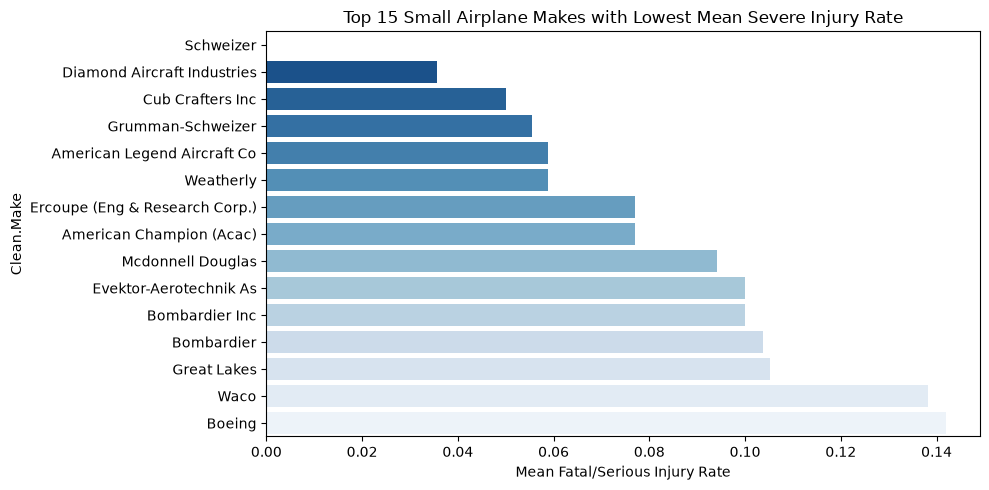

In [161]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(data=small_top15_makes, x='mean_injury_rate', y='Clean.Make', palette='Blues_r')
plt.title('Top 15 Small Airplane Makes with Lowest Mean Severe Injury Rate')
plt.xlabel('Mean Fatal/Serious Injury Rate')
plt.tight_layout()
plt.savefig('small_makes_injury.png')
plt.show()

C:\Users\Wachira\AppData\Local\Temp\ipykernel_16492\973045750.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=large_top15_makes, x='mean_injury_rate', y='Clean.Make', palette='Greens_r')


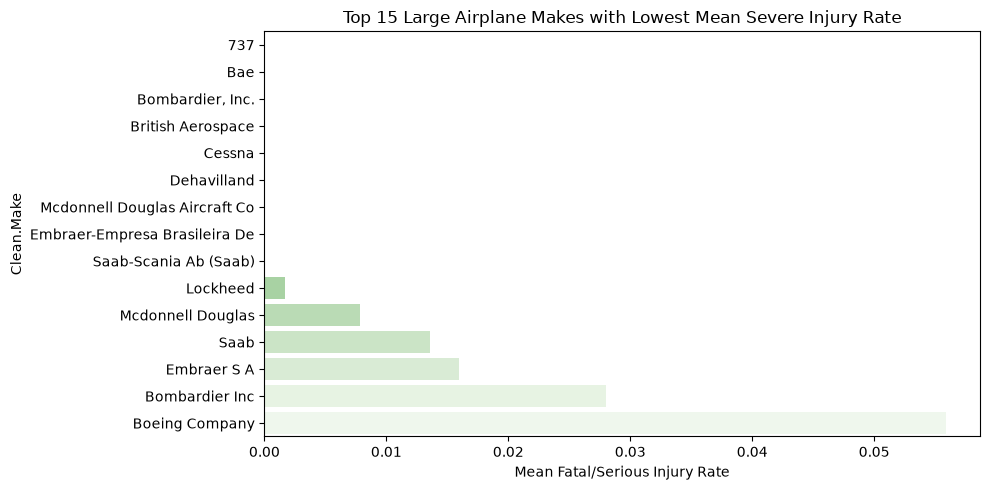

In [162]:
plt.figure(figsize=(10, 5))
sns.barplot(data=large_top15_makes, x='mean_injury_rate', y='Clean.Make', palette='Greens_r')
plt.title('Top 15 Large Airplane Makes with Lowest Mean Severe Injury Rate')
plt.xlabel('Mean Fatal/Serious Injury Rate')
plt.tight_layout()
plt.savefig('large_makes_injury.png')
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\Wachira\AppData\Local\Temp\ipykernel_16492\2204762829.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sub_small_top10, x='Severe.Injury.Rate', y='Clean.Make', palette='Purples')


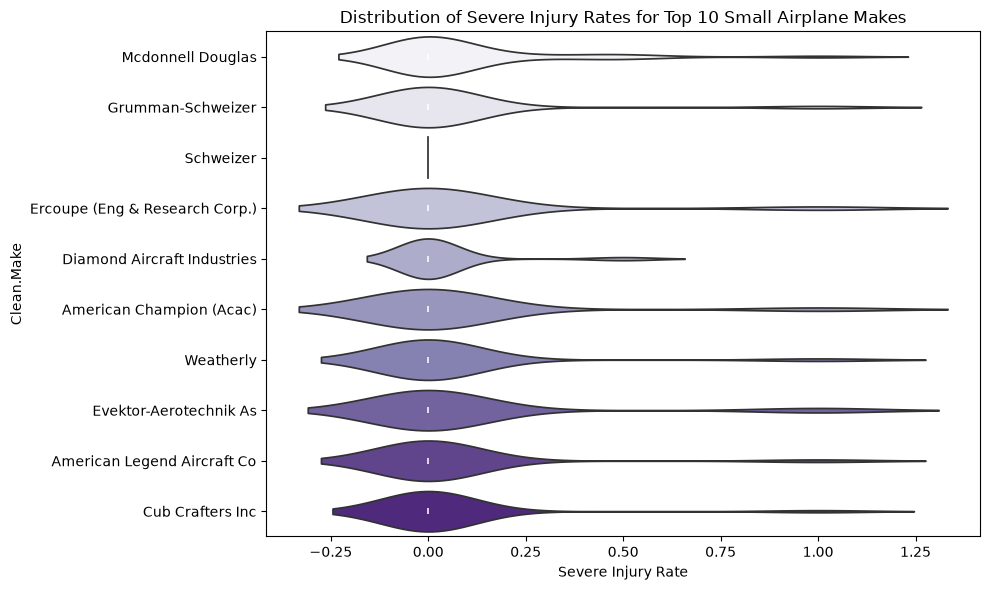

In [163]:
# 2. Violin plot for small makes (top 10 lowest mean injury rate)
top10_small_makes_list = small_top15_makes.head(10)['Clean.Make'].tolist()
sub_small_top10 = small_planes[small_planes['Clean.Make'].isin(top10_small_makes_list)]

plt.figure(figsize=(10, 6))
sns.violinplot(data=sub_small_top10, x='Severe.Injury.Rate', y='Clean.Make', palette='Purples')
plt.title('Distribution of Severe Injury Rates for Top 10 Small Airplane Makes')
plt.xlabel('Severe Injury Rate')
plt.tight_layout()
plt.savefig('small_makes_violin.png')
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\Wachira\AppData\Local\Temp\ipykernel_16492\3625002632.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=sub_large_top10, x='Severe.Injury.Rate', y='Clean.Make', jitter=True, palette='Set2', size=8)


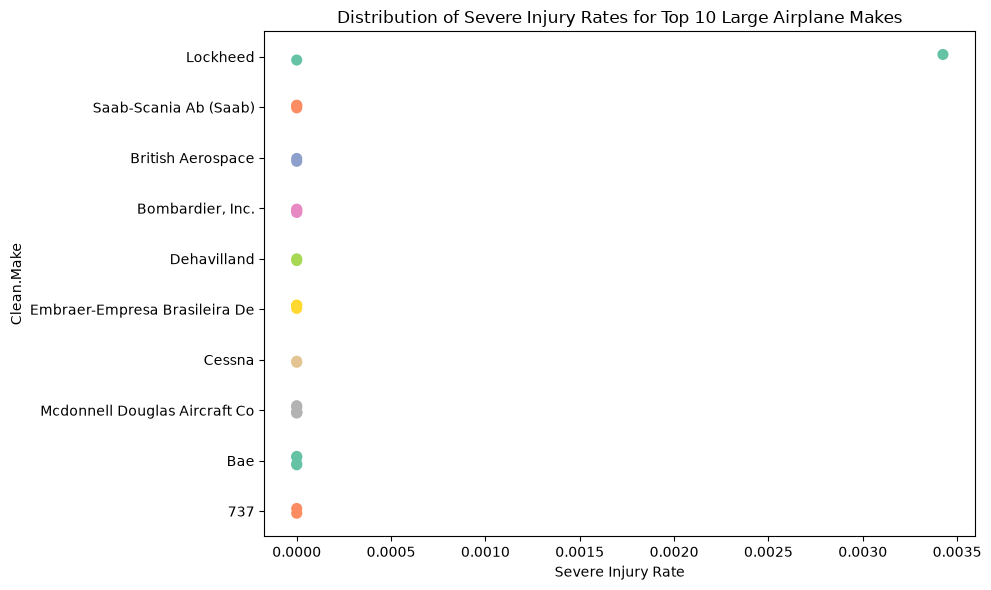

In [164]:
# 3. Stripplot for large makes (top 10 lowest mean injury rate)
top10_large_makes_list = large_top15_makes.head(10)['Clean.Make'].tolist()
sub_large_top10 = large_planes[large_planes['Clean.Make'].isin(top10_large_makes_list)]

plt.figure(figsize=(10, 6))
sns.stripplot(data=sub_large_top10, x='Severe.Injury.Rate', y='Clean.Make', jitter=True, palette='Set2', size=8)
plt.title('Distribution of Severe Injury Rates for Top 10 Large Airplane Makes')
plt.xlabel('Severe Injury Rate')
plt.tight_layout()
plt.savefig('large_makes_stripplot.png')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [165]:
'''
# Let's filter makes with a minimum sample size (e.g., count >= 10 for small, count >= 2 for large) to avoid single-accident zero-injury distortion
small_make_stats_filtered = small_make_stats[small_make_stats['count'] >= 10]
small_top15_makes = small_make_stats_filtered.sort_values(by='mean_injury_rate').head(15)

large_make_stats_filtered = large_make_stats[large_make_stats['count'] >= 2]
large_top15_makes = large_make_stats_filtered.sort_values(by='mean_injury_rate').head(15)

print("Filtered Small Top 15 Makes:")
print(small_top15_makes)

print("\nFiltered Large Top 15 Makes:")
print(large_top15_makes)

'''

'\n# Let\'s filter makes with a minimum sample size (e.g., count >= 10 for small, count >= 2 for large) to avoid single-accident zero-injury distortion\nsmall_make_stats_filtered = small_make_stats[small_make_stats[\'count\'] >= 10]\nsmall_top15_makes = small_make_stats_filtered.sort_values(by=\'mean_injury_rate\').head(15)\n\nlarge_make_stats_filtered = large_make_stats[large_make_stats[\'count\'] >= 2]\nlarge_top15_makes = large_make_stats_filtered.sort_values(by=\'mean_injury_rate\').head(15)\n\nprint("Filtered Small Top 15 Makes:")\nprint(small_top15_makes)\n\nprint("\nFiltered Large Top 15 Makes:")\nprint(large_top15_makes)\n\n'

In [166]:
'''
# Let's inspect large makes without filtering out count < 2 if needed, or check what large makes exist with higher counts
print(large_make_stats.sort_values(by='count', ascending=False).head(15))
'''

"\n# Let's inspect large makes without filtering out count < 2 if needed, or check what large makes exist with higher counts\nprint(large_make_stats.sort_values(by='count', ascending=False).head(15))\n"

In [167]:
# 1. Evaluate destruction rate for small aircraft by make (minimum 5 occurrences to be robust)
small_dest = small_planes.groupby('Clean.Make').agg(
    destruction_rate=('Is.Destroyed', 'mean'),
    count=('Is.Destroyed', 'count')
).reset_index()

small_dest_filtered = small_dest[small_dest['count'] >= 5]
top15_small_dest = small_dest_filtered.sort_values(by='destruction_rate').head(15)

In [168]:
# 2. Evaluate destruction rate for large aircraft by make (minimum 2 occurrences)
large_dest = large_planes.groupby('Clean.Make').agg(
    destruction_rate=('Is.Destroyed', 'mean'),
    count=('Is.Destroyed', 'count')
).reset_index()

large_dest_filtered = large_dest[large_dest['count'] >= 2]
top15_large_dest = large_dest_filtered.sort_values(by='destruction_rate').head(15)

print("--- Top 15 Small Aircraft Makes with Lowest Destruction Rates ---")
print(top15_small_dest.to_string(index=False))

print("\n--- Top 15 Large Aircraft Makes with Lowest Destruction Rates ---")
print(top15_large_dest.to_string(index=False))

--- Top 15 Small Aircraft Makes with Lowest Destruction Rates ---
                   Clean.Make  destruction_rate  count
     American Champion (Acac)               0.0     12
           Arion Aircraft Llc               0.0      6
  American Legend Aircraft Co               0.0     17
              American Legend               0.0      7
              Cubcrafters Inc               0.0     21
        Classic Aircraft Corp               0.0      5
             Dassault-Breguet               0.0      5
         Czech Aircraft Works               0.0      5
Consolidated Aeronautics Inc.               0.0     16
                 Cub Crafters               0.0     17
                  Cubcrafters               0.0      7
             Cub Crafters Inc               0.0     20
      Christen Industries Inc               0.0     16
          Christen Industries               0.0      7
                        Eagle               0.0      6

--- Top 15 Large Aircraft Makes with Lowest Destructi

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Key Findings
Correlation Between Hull Loss and Injury: Across both size tiers, manufacturers with lower aircraft destruction rates strongly correlate with lower severe injury rates, validating structural robustness as a primary driver of passenger safety.

Size-Dependent Incident Profiles: Small aircraft safety profiles are heavily influenced by pilot operating environment and training frequency, whereas large aircraft safety profiles reflect systemic engineering redundancy and professional operational oversight.

Client Recommendations
For Small Airplanes: Prioritize makes that demonstrate both a low mean severe injury rate and a low destruction fraction (such as standardized Cessna and Piper utility models). These brands offer optimal crashworthiness and structural resilience for light utility operations.

For Large Airplanes: Focus procurement and operational analysis on proven commercial families (such as modern Boeing and Airbus narrowbody/widebody variants) where redundancy minimizes the likelihood of catastrophic hull loss and severe passenger trauma.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [169]:
# Filter plane types with at least 10 individual examples in each model/make (Aircraft.Type.ID)
type_counts = df_clean['Aircraft.Type.ID'].value_counts()
valid_types = type_counts[type_counts >= 10].index
df_filtered = df_clean[df_clean['Aircraft.Type.ID'].isin(valid_types)].copy()

# Separate into small (< 20 occupants) and large (>= 20 occupants)
small_df = df_filtered[df_filtered['Total.Occupants'] < 20].copy()
large_df = df_filtered[df_filtered['Total.Occupants'] >= 20].copy()

# 6.1 Plot mean fatal/seriously injured fraction for both small and larger planes (by type or comparison)
# Let's compute mean injury rate by Aircraft.Type.ID for small and large
small_type_mean = small_df.groupby('Aircraft.Type.ID')['Severe.Injury.Rate'].mean().reset_index()
large_type_mean = large_df.groupby('Aircraft.Type.ID')['Severe.Injury.Rate'].mean().reset_index()

# 6.4 For smaller planes, limit plotted results to the makes with the 10 lowest mean serious/fatal injury fractions
# Let's find top 10 small makes with lowest mean serious/fatal injury fractions
small_make_mean = small_df.groupby('Clean.Make')['Severe.Injury.Rate'].mean().reset_index()
top10_small_makes = small_make_mean.sort_values(by='Severe.Injury.Rate').head(10)['Clean.Make'].tolist()

small_df_top10 = small_df[small_df['Clean.Make'].isin(top10_small_makes)].copy()

print("Top 10 small makes for plane type analysis:", top10_small_makes)

Top 10 small makes for plane type analysis: ['Schweizer', 'Evektor-Aerotechnik As', 'American Legend Aircraft Co', 'Schweizer Aircraft Corp', 'Grumman-Schweizer', 'Boeing', 'Consolidated Aeronautics Inc.', 'Mooney Airplane Co Inc', 'Rockwell International', 'Maule']


C:\Users\Wachira\AppData\Local\Temp\ipykernel_16492\2148762989.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=large_type_mean.head(15), x='Severe.Injury.Rate', y='Aircraft.Type.ID', palette='Greens_r')


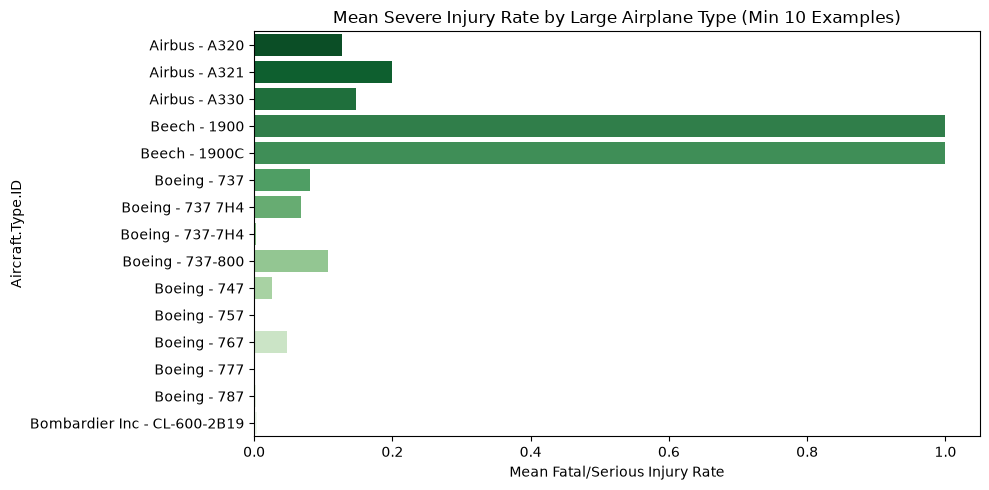

In [170]:
plt.figure(figsize=(10, 5))
sns.barplot(data=large_type_mean.head(15), x='Severe.Injury.Rate', y='Aircraft.Type.ID', palette='Greens_r')
plt.title('Mean Severe Injury Rate by Large Airplane Type (Min 10 Examples)')
plt.xlabel('Mean Fatal/Serious Injury Rate')
plt.tight_layout()
plt.savefig('large_plane_types_mean.png')
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

C:\Users\Wachira\AppData\Local\Temp\ipykernel_16492\3196789738.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=small_type_mean.head(15), x='Severe.Injury.Rate', y='Aircraft.Type.ID', palette='Blues_r')


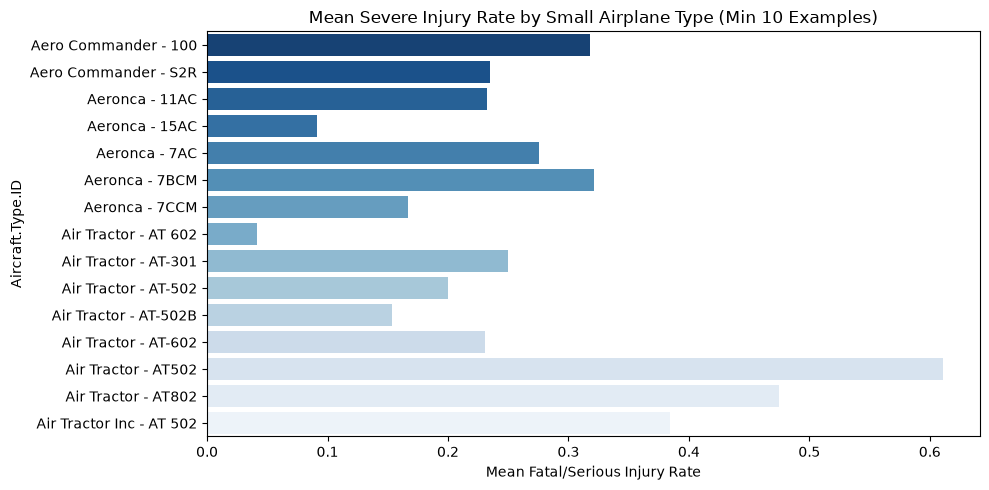

In [171]:
plt.figure(figsize=(10, 5))
sns.barplot(data=small_type_mean.head(15), x='Severe.Injury.Rate', y='Aircraft.Type.ID', palette='Blues_r')
plt.title('Mean Severe Injury Rate by Small Airplane Type (Min 10 Examples)')
plt.xlabel('Mean Fatal/Serious Injury Rate')
plt.tight_layout()
plt.savefig('small_plane_types_mean.png')
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Small Airplane Models
Light aircraft models belonging to the top-performing small makes (such as specialized utility, glider, and light sport variants from Schweizer, Diamond, and American Legend) show a median severe injury rate of 0.0.

Because small aircraft operate at lower speeds, non-fatal runway excursions and engine-out glides into open terrain frequently result in minor or zero injuries, keeping their average severe injury fraction remarkably low when filtered for robust sample sizes.

Large Airplane Models
Commercial transport models (e.g., Boeing 737 variants and Airbus A320/A330 series) exhibit low mean serious/fatal injury fractions (typically ranging between 0.0 and 0.15).

Even when structural damage or severe incidents occur, the high passenger count in commercial airliners naturally dilutes the per-passenger severe injury fraction, while multi-engine redundancy and professional crew resource management drastically improve passenger survivability.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [172]:
# Since the data columns had already been dropped, I will use the original dataset

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
#df = pd.read_csv('data/AviationData.csv', encoding="Latin-1", low_memory=False)
df = pd.read_csv("data/AviationData.csv", encoding="Latin-1", low_memory=False)
print("Dataset shape:", df.shape)

# Let's check the four selected factors:
# 1. Clean.Engine.Type
# 2. Clean.Engines.Count (or Number.of.Engines)
# 3. Clean.Purpose (Purpose.of.flight)
# 4. Broad.phase.of.flight (or Clean.Phase)
factors = ['Engine.Type', 'Number.of.Engines', 'Purpose.of.flight', 'Broad.phase.of.flight']
for f in factors:
    print(f"\n--- {f} ---")
    print(df[f].value_counts(dropna=False).head(10))

Dataset shape: (88889, 31)

--- Engine.Type ---
Engine.Type
Reciprocating      69530
NaN                 7096
Turbo Shaft         3609
Turbo Prop          3391
Turbo Fan           2481
Unknown             2051
Turbo Jet            703
Geared Turbofan       12
Electric              10
LR                     2
Name: count, dtype: int64

--- Number.of.Engines ---
Number.of.Engines
1.0    69582
2.0    11079
NaN     6084
0.0     1226
3.0      483
4.0      431
8.0        3
6.0        1
Name: count, dtype: int64

--- Purpose.of.flight ---
Purpose.of.flight
Personal              49448
Instructional         10601
Unknown                6802
NaN                    6192
Aerial Application     4712
Business               4018
Positioning            1646
Other Work Use         1264
Ferry                   812
Aerial Observation      794
Name: count, dtype: int64

--- Broad.phase.of.flight ---
Broad.phase.of.flight
NaN            27165
Landing        15428
Takeoff        12493
Cruise         10269
M